# AI and Emerging Technologies
## A Program by IIT Hyderabad and TalentSprint

### Playground Challenge Notebook: Meme Image Classification

## Introduction

Memes are a popular form of online communication that combine images and text
to express opinions, emotions, humour, and social commentary.

Understanding the sentiment of a meme is challenging because its meaning often
depends on both the **visual content** and the **text present in the image**.
Analyzing only one of these modalities may not capture the complete context.

In this challenge, we will build a **Multimodal Sentiment Classification Model**
that combines:

- **Image features** extracted from meme images
- **Text features** extracted from the corrected meme text

The model will learn from both modalities and classify each meme into one of
five sentiment categories.

## About the Dataset

The dataset contains **6,992 labeled meme images** along with text extracted
from each meme and its corresponding sentiment label.

The CSV file contains the following columns:

| Column | Description |
|---|---|
| `image_name` | Name of the corresponding meme image |
| `text_ocr` | Text automatically extracted from the meme using OCR |
| `text_corrected` | Corrected version of the extracted meme text |
| `overall_sentiment` | Sentiment label assigned to the meme |

The `Unnamed: 0` column is an index column and is not required for model
development.

The target variable is:

`overall_sentiment`

The dataset contains five sentiment classes:

- `very_positive`
- `positive`
- `neutral`
- `negative`
- `very_negative`

The `image_name` column will be used to locate the corresponding image in the
image folder, while `text_corrected` will be used as the textual input to the
multimodal model.

## Problem Statement

To design and implement a **Multimodal Deep Learning Model** that combines
visual information from meme images with textual information from meme captions
to classify the overall sentiment of a meme.

The model should predict one of the following sentiment classes:

- Very Positive
- Positive
- Neutral
- Negative
- Very Negative

The challenge involves:

1. Loading and understanding the labeled meme dataset
2. Mapping image names to their corresponding image files
3. Preprocessing meme images
4. Cleaning and tokenizing corrected meme text
5. Building separate image and text feature extraction branches
6. Combining both modalities using feature fusion
7. Training and validating the multimodal model
8. Evaluating its performance on unseen data

## Grading = 100 Marks

Here is a handy link to Kaggle's competition (https://www.kaggle.com/competitions/multimodal-classification-of-meme-images-with-labels/).

## Instructions for downloading train and test dataset from Kaggle API are as follows:

### 1. Create an API key in Kaggle.

To do this, go to the competition site on Kaggle at (https://www.kaggle.com/competitions/multimodal-classification-of-meme-images-with-labels/) and open your user settings page. Click Account.

* Click on your profile picture at the top-right corner of the page.

![alt text](https://i.imgur.com/kSLmEj2.png)

* In the popout menu, click the Settings option.

![alt text](https://i.imgur.com/tNi6yun.png)








In [1]:
!pip install -q "protobuf<6" "requests==2.32.4"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.3 which is incompatible.


In [2]:
!pip install --upgrade --force-reinstall kaggle


  Using cached kaggle-2.2.4-py3-none-any.whl.metadata (17 kB)
  Using cached bleach-6.4.0-py3-none-any.whl.metadata (32 kB)
  Using cached jupytext-1.19.6-py3-none-any.whl.metadata (15 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl.metadata (595 bytes)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
  Using cached python_slugify-9.1.3-py3-none-any.whl.metadata (12 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached webencodings-0.6.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdit_py_plugins-0.6.1-p

### 2. Generate a Kaggle API token

Open [Kaggle API settings](https://www.kaggle.com/settings/api), scroll to **API**, and click **Generate New Token**.

Copy the token string (it starts with `KGAT_`). That string is what Colab will store in `KAGGLE_API_TOKEN`. Do not paste it into this notebook.
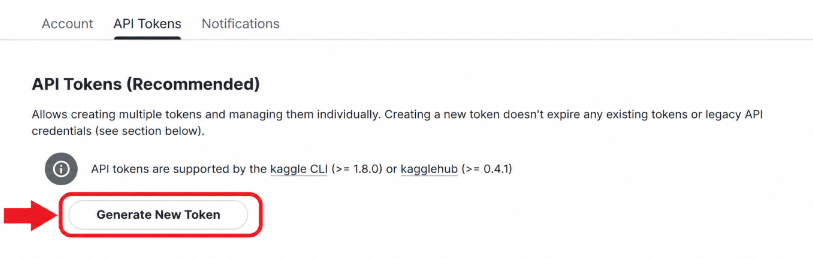


### 3. Authenticate with Kaggle using the Kaggle API Token

Kaggle now supports API tokens through the `KAGGLE_API_TOKEN` environment variable.

We will store the API token securely in **Google Colab Secrets** instead of directly writing the token in the notebook.

**Steps:**
1. Open the **Secrets (🔑)** tab in the left sidebar of Google Colab.
2. Add a new secret with the name:

`KAGGLE_API_TOKEN`

3. Paste your Kaggle API token as the value.
4. Make sure notebook access is enabled for this secret.

### Load the Kaggle Token

In [3]:
import os
from google.colab import userdata

# Name in Colab Secrets must be exactly KAGGLE_API_TOKEN, with notebook access on.
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")


In [4]:
# Verify that the token is available
print("Kaggle API token loaded:", bool(os.environ.get("KAGGLE_API_TOKEN")))

Kaggle API token loaded: True


### 4. Verify Kaggle API Authentication

Let's verify that the Kaggle API is properly configured by listing the files available in the competition.

The competition is:

**Multimodal Sentiment Classification**

Competition URL: https://www.kaggle.com/competitions/multimodal-classification-of-meme-images-with-labels/



In [5]:
!kaggle competitions files multimodal-classification-of-meme-images-with-labels

Next Page Token = CfDJ8JDwKpgsc5hJpcljKjpYpOFQOhgqfyCHThUX1N-aop9ssYtT05LmEY5N4WTvzw8nXaaaentXgrXcbOjU4Rjyk_rF0m2yuGmXlbUuQEQSHXncrP-GWby8dpD_CtZ5niwxPnOHmzenYCTyV8lAxn3yFps
name                         size  creationDate                
---------------------  ----------  --------------------------  
images/image_1.jpg          88087  2026-09-24 20:00:20.854000  
images/image_10.png        328876  2026-09-24 19:45:37.370000  
images/image_100.jpg       135332  2026-09-24 19:45:37.915000  
images/image_1000.png      192693  2026-09-24 19:46:05.566000  
images/image_1001.png      121946  2026-09-24 19:46:08.163000  
images/image_1002.png      179575  2026-09-24 19:52:04.819000  
images/image_1003.png       90617  2026-09-24 20:15:11.956000  
images/image_1004.png      237557  2026-09-24 19:46:08.406000  
images/image_1005.jpg       51612  2026-09-24 19:46:06.559000  
images/image_1006.png      131696  2026-09-24 19:46:08.762000  
images/image_1007.jpg      120200  2026-09-24 19:46:08.500

### 5. Download the Competition Data from Kaggle

We will now download the complete dataset from the **Multimodal Sentiment Classification** competition.

The downloaded files will be stored inside:

`/content/multimodal_data`

**NOTE:** You must have joined the Kaggle competition and accepted its competition rules before downloading the competition data.

If you receive a **403/Forbidden** or **404/Not Found** error, check whether you have joined the competition and accepted its rules on Kaggle.

In [6]:
# Labeled training dataset (6992 memes) — community dataset on Kaggle
!mkdir -p /content/meme_dataset

!kaggle datasets download \
    -d hammadjavaid/6992-labeled-meme-images-dataset \
    -p /content/meme_dataset


mkdir: /content: Read-only file system
Dataset URL: https://www.kaggle.com/datasets/hammadjavaid/6992-labeled-meme-images-dataset
License(s): GPL-2.0
[Errno 30] Read-only file system: '/content'


### 6. Extract the Downloaded Dataset

The Kaggle competition data is downloaded as a ZIP file.

We will extract the contents into the same folder.

In [7]:
!unzip -q /content/meme_dataset/*.zip -d /content/meme_dataset


zsh:1: no matches found: /content/meme_dataset/*.zip


### 7. Verify the Downloaded Dataset

Let's check the files and folders downloaded from Kaggle.

In [8]:
import os

for root, dirs, files in os.walk("/content/meme_dataset"):
    level = root.replace("/content/meme_dataset", "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")


### 8. Competition test data (2099 rows) + Google Drive cache

Faced issue witht provides `test.csv` and `sample_submission.csv` (2099 rows each) from the **Kaggle competition** .
They are **not** in the 6992-image training dataset zip.

This block:
1. Mounts Google Drive (one-time click per Colab session).
2. Restores cached competition files from Drive if available.
3. Otherwise downloads from `kaggle competitions download`.
4. Copies `test.csv`, `sample_submission.csv`, and test images back to Drive for the **next** session.
5. This is created for our ease of testing across the team, this is not part of any core logic


In [9]:
import shutil
import zipfile
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

COMPETITION_DIR = Path("/content/competition_data")
DRIVE_CACHE = Path("/content/drive/MyDrive/AIET_meme_kaggle_cache")
COMPETITION_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_CACHE.mkdir(parents=True, exist_ok=True)

COMPETITION_SLUG = "multimodal-classification-of-meme-images-with-labels"


def cache_file(name: str) -> None:
    src = COMPETITION_DIR / name
    dst = DRIVE_CACHE / name
    if src.exists():
        shutil.copy2(src, dst)
    elif dst.exists() and not src.exists():
        shutil.copy2(dst, src)


for fname in ["test.csv", "sample_submission.csv"]:
    cache_file(fname)

for folder in ["test", "images", "test_images"]:
    src_dir = DRIVE_CACHE / folder
    dst_dir = COMPETITION_DIR / folder
    if src_dir.is_dir() and not dst_dir.exists():
        shutil.copytree(src_dir, dst_dir)

need_download = not (COMPETITION_DIR / "test.csv").exists() or not (
    COMPETITION_DIR / "sample_submission.csv"
).exists()
if need_download:
    print("Downloading competition files from Kaggle...")
    !kaggle competitions download -c multimodal-classification-of-meme-images-with-labels -p /content/competition_data
    for z in COMPETITION_DIR.glob("*.zip"):
        with zipfile.ZipFile(z, "r") as zf:
            zf.extractall(COMPETITION_DIR)
else:
    print("Using cached competition files (skip download).")

for fname in ["test.csv", "sample_submission.csv"]:
    cache_file(fname)

for folder in ["test", "images", "test_images"]:
    src_dir = COMPETITION_DIR / folder
    dst_dir = DRIVE_CACHE / folder
    if src_dir.is_dir() and not dst_dir.exists():
        shutil.copytree(src_dir, dst_dir)

print("COMPETITION_DIR:", COMPETITION_DIR)
print("test.csv:", (COMPETITION_DIR / "test.csv").exists())
print("sample_submission.csv:", (COMPETITION_DIR / "sample_submission.csv").exists())


ModuleNotFoundError: No module named 'google.colab'

## YOUR CODING STARTS FROM HERE

## Import required packages

In [ ]:
# Import required packages
!pip install -q "transformers>=4.44"

import os
import re
import random
import hashlib
import contextlib
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image, ImageFile
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    CLIPModel,
    CLIPProcessor,
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    log_loss,
)

# --- Hyperparameters / CONFIG ---
# Both backbones are frozen: features are extracted once (and cached on Drive), then a
# small fusion head is trained. Fine-tuning on ~7k noisy labels fell below the
# majority baseline, frozen features + a regularised head do not.
CLIP_MODEL_NAME = "openai/clip-vit-large-patch14"          # image + caption (aligned space)
SENTIMENT_MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"  # caption sentiment
SENTIMENT_FALLBACK_NAME = "distilbert-base-uncased-finetuned-sst-2-english"
CLIP_TEXT_MAX_LEN = 77
SENT_TEXT_MAX_LEN = 128
IMG_SIZE = 224
EXTRACT_BATCH_SIZE = 64
FEATURE_CACHE_DIR = Path("/content/drive/MyDrive/AIET_meme_features")

HIDDEN_DIM = 256
DROPOUT = 0.4
MODALITY_DROPOUT = 0.2      # per-sample chance of blanking the image OR the text branch
BATCH_SIZE = 128
EPOCHS = 60
LR = 5e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
EARLY_STOP_PATIENCE = 8
SELECTION_METRIC = "loss"   # "loss" (smoother) or "accuracy"
N_FOLDS = 5
LOGREG_C = 0.05
NUM_CLASSES = 5
RANDOM_SEED = 42

# Final decision rule: per-class logit offsets tuned on out-of-fold predictions to maximise
#   accuracy + BALANCE_WEIGHT * macro-F1
# 0.0 = pure leaderboard accuracy (tends to predict mostly "positive");
# larger values spread predictions across classes at a small accuracy cost.
BALANCE_WEIGHT = 0.1


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(RANDOM_SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)


def amp_ctx():
    if device.type == "cuda":
        return torch.autocast("cuda", dtype=torch.float16)
    return contextlib.nullcontext()


SENTIMENT_CLASSES = [
    "very_positive", "positive", "neutral", "negative", "very_negative"
]
LABEL_TO_IDX = {c: i for i, c in enumerate(SENTIMENT_CLASSES)}
IDX_TO_LABEL = {i: c for c, i in LABEL_TO_IDX.items()}

DATA_DIR = Path("/content/meme_dataset")
COMPETITION_DIR = Path("/content/competition_data")
print("DATA_DIR:", DATA_DIR.resolve())
print("COMPETITION_DIR:", COMPETITION_DIR.resolve())
if Path("/content/drive/MyDrive").exists():
    FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
else:
    FEATURE_CACHE_DIR = Path("/content/feature_cache")
    FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Loading CLIP processor and sentiment tokenizer...")
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_tokenizer = clip_processor.tokenizer
sent_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_NAME)
print("CLIP:", CLIP_MODEL_NAME, "| sentiment text model:", SENTIMENT_MODEL_NAME)

##   **Stage 1**: Dataset Loading & Understanding (10 Marks)

#### Task 1.1: Load and Inspect the Labels Dataset


In [ ]:
# Load the labels dataset into a pandas DataFrame
df = pd.read_csv(DATA_DIR / "labels.csv")
df.head()


#### Task 1.2: Analyze Data Quality (Examine the dataset)

In [ ]:
# YOUR CODE HERE
df.info()

print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows (before drop):", df.duplicated().sum())

# Drop exact duplicate rows for cleaner training signal
dup_count = df.duplicated().sum()
if dup_count:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Dropped {dup_count} duplicate rows; remaining:", len(df))

print("\nUnique values:\n", df.nunique())
print("\nRows with null text_corrected:")
display(df[df["text_corrected"].isnull()].head())


In [ ]:
df.drop(columns=["Unnamed: 0"], inplace=True, errors="ignore")

#### Task 1.3: Analyze Sentiment Distribution

In [ ]:
# YOUR CODE HERE — sentiment distribution
print(df["overall_sentiment"].value_counts())
print("\nPercent:")
print(df["overall_sentiment"].value_counts(normalize=True) * 100)

majority_frac = df["overall_sentiment"].value_counts(normalize=True).max()
print(f"\nMajority-class baseline accuracy (always predict mode): {majority_frac:.4f}")

sns.countplot(data=df, x="overall_sentiment", order=SENTIMENT_CLASSES)
plt.xticks(rotation=30)
plt.title("Sentiment class distribution (imbalanced — weight loss / metrics matter)")
plt.tight_layout()
plt.show()


**Observation (Stage 1):** Classes are imbalanced (~45% positive, ~31% neutral, very_negative only ~2%). The leaderboard scores accuracy, so we do not upweight rare classes in the loss. Instead the final decision rule tunes per-class logit offsets on out-of-fold predictions (Task 6.2), which controls how strongly predictions collapse onto "positive". Macro-F1 and per-class recall are reported alongside accuracy.

##   **Stage 2**: Image Data Preprocessing (15 Marks)

#### Task 2.1: Map Image Names to Image Files

In [ ]:
# Map image_name -> file path under DATA_DIR

IMAGE_EXTS = {".jpg", ".jpeg", ".jpe", ".jfif", ".png", ".gif", ".webp", ".bmp"}


def build_image_lookup(data_dir: Path):
    lookup = {}
    for p in data_dir.rglob("*"):
        if p.suffix.lower() in IMAGE_EXTS:
            lookup[p.name] = p
            lookup[p.stem] = p
    return lookup


image_lookup = build_image_lookup(DATA_DIR)


def resolve_image_path(name):
    if pd.isna(name):
        return None
    name = str(name).strip()
    for key in (name, Path(name).name, Path(name).stem):
        if key in image_lookup:
            return str(image_lookup[key])
    return None


def load_rgb_image(path: str, fallback_size=IMG_SIZE):
    try:
        return Image.open(path).convert("RGB")
    except Exception as exc:
        print(f"Warning: could not load {path!r} ({exc}); using blank image")
        return Image.new("RGB", (fallback_size, fallback_size), color=(128, 128, 128))


df["image_path"] = df["image_name"].apply(resolve_image_path)
mapped = df["image_path"].notna().sum()
print(f"Mapped {mapped}/{len(df)} images")
df = df.dropna(subset=["image_path"]).reset_index(drop=True)
print(f"Training rows with valid image paths: {len(df)}")


#### Task 2.2: Visualize Sample Meme Images

In [ ]:
# Visualize sample memes
sample_df = df.sample(n=min(6, len(df)), random_state=RANDOM_SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()
for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = load_rgb_image(row["image_path"])
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"{row['overall_sentiment']}\n{str(row.get('text_corrected', ''))[:60]}", fontsize=9)
plt.tight_layout()
plt.show()


#### Task 2.3: Preprocess Meme Images

In [ ]:
# CLIP preprocessing: resize shortest side to 224, center-crop, CLIP mean/std.
# No random crop / flip: they cut or mirror the meme text. The vision tower is frozen
# and features are extracted once, so no train-time augmentation is applied.

def transform_image(image: Image.Image):
    pixels = clip_processor(images=image, return_tensors="pt")["pixel_values"]
    return pixels.squeeze(0)


sample_pixels = transform_image(load_rgb_image(df.iloc[0]["image_path"]))
print(
    "CLIP image preprocess ready | tensor",
    tuple(sample_pixels.shape),
    "| mean",
    tuple(round(x, 3) for x in clip_processor.image_processor.image_mean),
)

##   **Stage 3**: Text Data Preprocessing & Representation (15 Marks)

#### Task 3.1:  Handle Missing Text

In [ ]:
# Prefer text_corrected; fall back to text_ocr
if "text_corrected" not in df.columns:
    raise ValueError("Expected column text_corrected in labels.csv")
if "text_ocr" in df.columns:
    missing = df["text_corrected"].isna()
    df.loc[missing, "text_corrected"] = df.loc[missing, "text_ocr"].fillna("")
df["text_corrected"] = df["text_corrected"].fillna("")
print("Missing text_corrected after fill:", df["text_corrected"].isna().sum())


#### Task 3.2: Clean Meme Text

In [ ]:
# Light cleaning. Case and "!"/"?" carry sentiment for the RoBERTa sentiment model,
# so only URLs, meme-site watermarks and extra whitespace are removed.
WATERMARK_RE = re.compile(
    r"\b(?:imgflip|memegenerator|quickmeme|memecrunch|makeameme|9gag|ifunny|memecenter)\b",
    re.IGNORECASE,
)


def clean_text(text) -> str:
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ""
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w-]+\.(?:com|net|org|co|in)\b", " ", text, flags=re.IGNORECASE)
    text = WATERMARK_RE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df["text_clean"] = df["text_corrected"].apply(clean_text)
df[["text_corrected", "text_clean"]].head()

#### Task 3.3: Tokenize and Pad Text

In [ ]:
# Tokenize + pad for both text encoders (CLIP text tower and RoBERTa sentiment model),
# then a stratified train/val split. Tokenizers are pretrained, so nothing is fitted
# on validation text.

def tokenize_texts(texts, tokenizer, max_len):
    enc = tokenizer(
        [str(t) for t in texts],
        truncation=True,
        padding="max_length",
        max_length=max_len,
        return_attention_mask=True,
        return_tensors="np",
    )
    return enc["input_ids"].astype(np.int64), enc["attention_mask"].astype(np.int64)


clip_ids, clip_mask = tokenize_texts(df["text_clean"], clip_tokenizer, CLIP_TEXT_MAX_LEN)
sent_ids, sent_mask = tokenize_texts(df["text_clean"], sent_tokenizer, SENT_TEXT_MAX_LEN)

df["label_idx"] = df["overall_sentiment"].map(LABEL_TO_IDX)
assert df["label_idx"].notna().all(), "Unknown sentiment label in labels.csv"
y_all = df["label_idx"].to_numpy(dtype=np.int64)

train_idx, val_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_all,
)
train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print("CLIP tokens", clip_ids.shape, "| RoBERTa tokens", sent_ids.shape)
print("Train", len(train_idx), "| Val", len(val_idx))
print("Sample CLIP ids:", clip_ids[0][:12])
print("Sample RoBERTa ids:", sent_ids[0][:12])

**Task 3.3:** Captions are tokenized twice: with the CLIP tokenizer (77 tokens, for the CLIP text tower that shares an embedding space with the image tower) and with the RoBERTa tokenizer (128 tokens, for a Twitter sentiment model). The train/val split is stratified and done before any classifier is fit.

##   Stage 4: Multimodal Model Development (25 Marks)

#### Task 4.1: Build the Image Feature Extraction Branch

In [ ]:
# Image branch
# (a) Frozen CLIP ViT-L/14 vision tower + CLIP projection -> L2-normalised embedding,
#     extracted once per image and cached.
# (b) Trainable ImageBranch that projects the embedding for fusion.
# The full CLIPModel is loaded (not CLIPVisionModel): .vision_model and .visual_projection
# exist on both transformers 4.x and 5.x, whereas CLIPVisionModel has no .vision_model in 5.x.

clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(device).eval()
for p in clip_model.parameters():
    p.requires_grad = False
CLIP_DIM = clip_model.config.projection_dim


def cache_path(kind, keys):
    digest = hashlib.md5("|".join(map(str, keys)).encode()).hexdigest()[:12]
    model_tag = CLIP_MODEL_NAME.split("/")[-1]
    if kind != "img":
        model_tag += "_" + SENTIMENT_MODEL_NAME.split("/")[-1]
    return FEATURE_CACHE_DIR / f"{kind}_{model_tag}_{len(keys)}_{digest}.npy"


class ImagePathDataset(Dataset):
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        if path is None or path == "__missing__":
            image = Image.new("RGB", (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        else:
            image = load_rgb_image(path)
        return transform_image(image)


@torch.no_grad()
def extract_image_features(paths):
    paths = list(paths)
    cache = cache_path("img", paths)
    if cache.exists():
        print("Loaded cached image features:", cache.name)
        return np.load(cache)
    loader = DataLoader(
        ImagePathDataset(paths),
        batch_size=EXTRACT_BATCH_SIZE,
        shuffle=False,
        num_workers=2,
    )
    feats = []
    for i, pixels in enumerate(loader):
        with amp_ctx():
            vision_out = clip_model.vision_model(pixel_values=pixels.to(device))
            emb = clip_model.visual_projection(vision_out.pooler_output)
        feats.append(F.normalize(emb.float(), dim=-1).cpu().numpy())
        if i % 20 == 0:
            print(f"  image batch {i + 1}/{len(loader)}")
    feats = np.concatenate(feats).astype(np.float32)
    np.save(cache, feats)
    return feats


class ImageBranch(nn.Module):
    def __init__(self, in_dim=CLIP_DIM, out_dim=HIDDEN_DIM, dropout=DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Dropout(dropout / 2),
            nn.Linear(in_dim, out_dim),
            nn.GELU(),
        )

    def forward(self, x):
        return self.net(x)


image_feats = extract_image_features(df["image_path"].tolist())
print("Image features:", image_feats.shape, "| CLIP dim", CLIP_DIM)

#### Task 4.2: Build the Text Feature Extraction Branch

In [ ]:
# Text branch
# (a) Frozen encoders, extracted once per caption:
#     - CLIP text tower + projection (same space as the image embedding)
#     - Twitter RoBERTa sentiment model: mean-pooled last hidden state + its sentiment probs
# (b) Trainable TextBranch that projects the concatenated text features for fusion.

try:
    sent_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL_NAME)
except Exception as exc:
    print(f"Could not load {SENTIMENT_MODEL_NAME} ({exc}); falling back to {SENTIMENT_FALLBACK_NAME}")
    SENTIMENT_MODEL_NAME = SENTIMENT_FALLBACK_NAME
    sent_tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_NAME)
    sent_ids, sent_mask = tokenize_texts(df["text_clean"], sent_tokenizer, SENT_TEXT_MAX_LEN)
    sent_model = AutoModelForSequenceClassification.from_pretrained(SENTIMENT_MODEL_NAME)
sent_model = sent_model.to(device).eval()
for p in sent_model.parameters():
    p.requires_grad = False
SENT_LABELS = [sent_model.config.id2label[i] for i in range(sent_model.config.num_labels)]
TEXT_DIM = CLIP_DIM + sent_model.config.hidden_size + len(SENT_LABELS)


@torch.no_grad()
def extract_text_features(texts, c_ids, c_mask, s_ids, s_mask):
    """Returns [clip_text (CLIP_DIM) | roberta_mean (hidden) | roberta_probs]."""
    cache = cache_path("txt", list(texts))
    if cache.exists():
        print("Loaded cached text features:", cache.name)
        return np.load(cache)
    feats = []
    bs = EXTRACT_BATCH_SIZE * 2
    for start in range(0, len(c_ids), bs):
        sl = slice(start, start + bs)
        ci = torch.as_tensor(c_ids[sl], device=device)
        cm = torch.as_tensor(c_mask[sl], device=device)
        si = torch.as_tensor(s_ids[sl], device=device)
        sm = torch.as_tensor(s_mask[sl], device=device)
        with amp_ctx():
            clip_out = clip_model.text_model(input_ids=ci, attention_mask=cm)
            clip_emb = clip_model.text_projection(clip_out.pooler_output)
            sent_out = sent_model(input_ids=si, attention_mask=sm, output_hidden_states=True)
        clip_emb = F.normalize(clip_emb.float(), dim=-1)
        hidden = sent_out.hidden_states[-1].float()
        mask = sm.unsqueeze(-1).float()
        mean_emb = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1.0)
        probs = sent_out.logits.float().softmax(-1)
        feats.append(torch.cat([clip_emb, mean_emb, probs], dim=1).cpu().numpy())
    feats = np.concatenate(feats).astype(np.float32)
    np.save(cache, feats)
    return feats


class TextBranch(nn.Module):
    def __init__(self, in_dim=None, out_dim=HIDDEN_DIM, dropout=DROPOUT):
        super().__init__()
        in_dim = TEXT_DIM if in_dim is None else in_dim
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Dropout(dropout / 2),
            nn.Linear(in_dim, out_dim),
            nn.GELU(),
        )

    def forward(self, x):
        return self.net(x)


text_feats = extract_text_features(df["text_clean"].tolist(), clip_ids, clip_mask, sent_ids, sent_mask)
print("Text features:", text_feats.shape, "| sentiment labels", SENT_LABELS)

# How well does an off-the-shelf caption sentiment model line up with the meme labels?
sent_prob_df = pd.DataFrame(text_feats[:, -len(SENT_LABELS):], columns=SENT_LABELS)
sent_prob_df["overall_sentiment"] = df["overall_sentiment"].values
display(sent_prob_df.groupby("overall_sentiment")[SENT_LABELS].mean().loc[SENTIMENT_CLASSES].round(3))

#### Task 4.3: Fuse Image and Text Features

In [ ]:
# Gated late fusion of the projected image and text vectors.
#   z = [img, txt, img*txt, |img-txt|, g*img + (1-g)*txt, cos(clip_img, clip_txt)]
# g = sigmoid(W [img; txt]) lets the head decide per dimension which modality to trust.
# The CLIP image/caption cosine is a direct "does the caption match the picture" signal.

class GatedFusion(nn.Module):
    def __init__(self, dim=HIDDEN_DIM):
        super().__init__()
        self.gate = nn.Linear(2 * dim, dim)
        self.out_dim = 5 * dim + 1

    def forward(self, img_h, txt_h, clip_cos):
        g = torch.sigmoid(self.gate(torch.cat([img_h, txt_h], dim=1)))
        mixed = g * img_h + (1 - g) * txt_h
        return torch.cat(
            [img_h, txt_h, img_h * txt_h, (img_h - txt_h).abs(), mixed, clip_cos], dim=1
        )


fusion_dim = GatedFusion().out_dim
print("Fusion dim:", fusion_dim)

#### Task 4.4: Create and Compile the Multimodal Classifier

In [ ]:
# Multimodal classifier: image branch + text branch -> gated fusion -> MLP head.
# Modality dropout randomly blanks one branch per training sample, which regularises the
# head and makes the image-only / text-only ablations in Task 6.1 meaningful.

class MultimodalClassifier(nn.Module):
    def __init__(
        self,
        img_dim=CLIP_DIM,
        txt_dim=None,
        hidden=HIDDEN_DIM,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT,
        modality_dropout=MODALITY_DROPOUT,
    ):
        super().__init__()
        self.image_branch = ImageBranch(img_dim, hidden, dropout)
        self.text_branch = TextBranch(txt_dim, hidden, dropout)
        self.fusion = GatedFusion(hidden)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.fusion.out_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, num_classes),
        )
        self.modality_dropout = modality_dropout
        self.use_image = True
        self.use_text = True

    def forward(self, img, txt):
        b = img.size(0)
        img_keep = torch.full((b, 1), float(self.use_image), device=img.device)
        txt_keep = torch.full((b, 1), float(self.use_text), device=img.device)
        if self.training and self.modality_dropout > 0:
            r = torch.rand(b, 1, device=img.device)
            img_keep = img_keep * (r >= self.modality_dropout / 2).float()
            txt_keep = txt_keep * ((r < self.modality_dropout / 2) | (r >= self.modality_dropout)).float()
        img_h = self.image_branch(img) * img_keep
        txt_h = self.text_branch(txt) * txt_keep
        clip_cos = (img * txt[:, :CLIP_DIM]).sum(1, keepdim=True) * img_keep * txt_keep
        return self.classifier(self.fusion(img_h, txt_h, clip_cos))


criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)


def build_model_and_optimizer(steps_per_epoch, epochs=EPOCHS):
    model = MultimodalClassifier().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=LR,
        total_steps=steps_per_epoch * epochs,
        pct_start=0.1,
    )
    return model, optimizer, scheduler


model, _, _ = build_model_and_optimizer(steps_per_epoch=1)
n_total = sum(p.numel() for p in model.parameters())
n_frozen = sum(p.numel() for p in clip_model.parameters()) + sum(p.numel() for p in sent_model.parameters())
print(f"Trainable head parameters: {n_total:,} | frozen backbone parameters: {n_frozen:,}")
print(model)

##   **Stage 5**: Model Training  (20 Marks)

#### Task 5.1: Prepare Training Data

In [ ]:
# Training data: cached feature tensors indexed by the stratified split from Task 3.3.
X_img_all = torch.tensor(image_feats, dtype=torch.float32)
X_txt_all = torch.tensor(text_feats, dtype=torch.float32)
y_all_t = torch.tensor(y_all, dtype=torch.long)


def make_loader(idx, shuffle):
    idx = torch.as_tensor(np.asarray(idx), dtype=torch.long)
    ds = TensorDataset(X_img_all[idx], X_txt_all[idx], y_all_t[idx])
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=False)


train_loader = make_loader(train_idx, shuffle=True)
val_loader = make_loader(val_idx, shuffle=False)
print(f"Train {len(train_idx)} | Val {len(val_idx)} | batches/epoch {len(train_loader)}")

#### Task 5.2: Encode Sentiment Labels

In [ ]:
# Labels already encoded in Task 3.3
print("Label mapping:")
for c in SENTIMENT_CLASSES:
    print(c, "->", LABEL_TO_IDX[c])
train_df["label_idx"].value_counts().sort_index()

#### Task 5.3: Train the Multimodal Model

In [ ]:
# Train the fusion head. Checkpoint = best validation loss (or accuracy, see CONFIG).
# best_epoch is reused as a fixed training length for the CV folds in Task 6.2.

majority_baseline = float(df["overall_sentiment"].value_counts(normalize=True).max())
print(f"Majority-class baseline accuracy: {majority_baseline:.4f}")


def run_epoch(model, loader, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, n = 0.0, 0
    probs_all, labels_all = [], []
    for img, txt, labels in loader:
        img, txt, labels = img.to(device), txt.to(device), labels.to(device)
        with torch.set_grad_enabled(train):
            logits = model(img, txt)
            loss = criterion(logits, labels)
        if train:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
        loss_sum += loss.item() * labels.size(0)
        n += labels.size(0)
        probs_all.append(logits.detach().float().softmax(-1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs = np.concatenate(probs_all)
    labels = np.concatenate(labels_all)
    preds = probs.argmax(1)
    return (
        loss_sum / n,
        accuracy_score(labels, preds),
        f1_score(labels, preds, average="macro", zero_division=0),
        probs,
    )


def train_head(tr_idx, va_idx=None, stop_epoch=None, seed=RANDOM_SEED, verbose=False):
    """With va_idx: early stopping on validation. Without: train exactly stop_epoch epochs."""
    set_seed(seed)
    loader = make_loader(tr_idx, shuffle=True)
    model, optimizer, scheduler = build_model_and_optimizer(len(loader))
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_score, best_state, best_ep, stall = -np.inf, None, 0, 0
    last_epoch = stop_epoch or EPOCHS
    vloader = make_loader(va_idx, shuffle=False) if va_idx is not None else None
    for epoch in range(1, last_epoch + 1):
        tr_loss, tr_acc, _, _ = run_epoch(model, loader, optimizer, scheduler)
        if vloader is None:
            continue
        va_loss, va_acc, va_f1, va_probs = run_epoch(model, vloader)
        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc, va_f1)):
            history[k].append(v)
        score = -va_loss if SELECTION_METRIC == "loss" else va_acc
        if score > best_score:
            best_score, best_ep, stall = score, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stall += 1
        if verbose:
            print(
                f"Epoch {epoch:02d} | tr loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f} | "
                f"pred classes {len(np.unique(va_probs.argmax(1)))}"
            )
        if stall >= EARLY_STOP_PATIENCE:
            if verbose:
                print(f"Early stop: no val {SELECTION_METRIC} gain for {EARLY_STOP_PATIENCE} epochs")
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, history, best_ep or last_epoch


model, history, best_epoch = train_head(train_idx, val_idx, verbose=True)
best_val_acc = history["val_acc"][best_epoch - 1]
print(f"Best epoch {best_epoch} | val acc {best_val_acc:.4f} | baseline {majority_baseline:.4f}")
if best_val_acc <= majority_baseline:
    print("WARNING: validation accuracy is not above the majority-class baseline.")

#### Task 5.4: Analyze Training Performance

In [ ]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = range(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train")
axes[0].plot(ep, history["val_loss"], label="val")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch {best_epoch}")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(ep, history["val_acc"], label="val acc")
axes[1].plot(ep, history["val_macro_f1"], label="val macro-F1")
axes[1].axhline(majority_baseline, color="red", linestyle=":", label="majority baseline")
axes[1].axvline(best_epoch, color="gray", linestyle="--")
axes[1].set_title("Validation metrics")
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation (Stage 5.4):** The head trains on frozen features, so each epoch takes seconds. Validation loss bottoms out early and the train/val gap widens after that, which is why the checkpoint is chosen by validation loss. The red line is the majority-class baseline; the model only helps if validation accuracy is above it. Raw argmax predictions still lean towards "positive"; Task 6.2 corrects this with tuned class offsets.

##   **Stage 6**: Evaluation, Prediction & Submission (15 Marks)

#### Task 6.1: Evaluate the Model

In [ ]:
# Validation metrics, prediction distribution and ablation table

@torch.no_grad()
def predict_proba(model, X_img, X_txt, use_image=True, use_text=True):
    model.eval()
    model.use_image, model.use_text = use_image, use_text
    probs = []
    for start in range(0, len(X_img), 1024):
        img = X_img[start:start + 1024].to(device)
        txt = X_txt[start:start + 1024].to(device)
        probs.append(model(img, txt).float().softmax(-1).cpu().numpy())
    model.use_image, model.use_text = True, True
    return np.concatenate(probs)


def fit_logreg(tr_idx):
    X = np.hstack([image_feats, text_feats])
    scaler = StandardScaler().fit(X[tr_idx])
    clf = LogisticRegression(C=LOGREG_C, max_iter=3000)
    clf.fit(scaler.transform(X[tr_idx]), y_all[tr_idx])
    return lambda img, txt: clf.predict_proba(scaler.transform(np.hstack([img, txt])))


val_probs = predict_proba(model, X_img_all[val_idx], X_txt_all[val_idx])
val_preds = val_probs.argmax(1)
val_true = y_all[val_idx]
val_acc = accuracy_score(val_true, val_preds)
val_macro_f1 = f1_score(val_true, val_preds, average="macro", zero_division=0)
print("Validation accuracy:", round(val_acc, 4))
print("Majority baseline:", round(majority_baseline, 4))
print("Validation macro-F1:", round(val_macro_f1, 4))
print(classification_report(val_true, val_preds, target_names=SENTIMENT_CLASSES, zero_division=0))

dist = pd.DataFrame({
    "true": pd.Series(val_true).map(IDX_TO_LABEL).value_counts(normalize=True),
    "predicted": pd.Series(val_preds).map(IDX_TO_LABEL).value_counts(normalize=True),
}).reindex(SENTIMENT_CLASSES).fillna(0).round(3)
display(dist)

cm = confusion_matrix(val_true, val_preds, labels=list(range(NUM_CLASSES)))
cm_n = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=SENTIMENT_CLASSES, yticklabels=SENTIMENT_CLASSES, ax=ax[0])
sns.heatmap(cm_n, annot=True, fmt=".2f", xticklabels=SENTIMENT_CLASSES, yticklabels=SENTIMENT_CLASSES, ax=ax[1])
plt.tight_layout()
plt.show()

logreg_val = fit_logreg(train_idx)(image_feats[val_idx], text_feats[val_idx])
rows = [{"setup": "majority (always positive)", "accuracy": majority_baseline, "macro_f1": np.nan}]
for name, ui, ut in [("fusion", True, True), ("image_only", True, False), ("text_only", False, True)]:
    p = predict_proba(model, X_img_all[val_idx], X_txt_all[val_idx], ui, ut).argmax(1)
    rows.append({"setup": name, "accuracy": accuracy_score(val_true, p),
                 "macro_f1": f1_score(val_true, p, average="macro", zero_division=0)})
p = logreg_val.argmax(1)
rows.append({"setup": "logistic regression (all features)", "accuracy": accuracy_score(val_true, p),
             "macro_f1": f1_score(val_true, p, average="macro", zero_division=0)})
display(pd.DataFrame(rows).round(4))

#### Task 6.2: Generate Sentiment Predictions

In [ ]:
# Official test predictions
# 1. Load test.csv, resolve images, clean + tokenize captions, extract frozen features.
# 2. 5-fold CV over ALL labelled memes: each fold trains the fusion head (best_epoch epochs)
#    and a logistic regression; test probabilities are averaged over folds.
# 3. Out-of-fold (OOF) predictions pick the MLP/LogReg blend weight and per-class logit
#    offsets, so the final class mix is tuned on data the models did not train on.

TEXT_PRIMARY = [
    "text_corrected", "corrected_text", "text", "caption",
    "meme_text", "sentence", "cleaned_text",
]
TEXT_FALLBACK = ["text_ocr", "ocr", "ocr_text"]
IMAGE_NAME_COLS = ["image_name", "filename", "file_name", "image", "file", "img"]


def find_id_column(frame):
    for col in frame.columns:
        if col == "Id" or str(col).lower() == "id":
            return col
    for col in frame.columns:
        if str(col).lower() in {"image_name", "filename", "file", "image"}:
            return col
    return frame.columns[0]


def find_named_column(frame, names):
    lookup = {str(c).lower().strip(): c for c in frame.columns}
    for name in names:
        if name in lookup:
            return lookup[name]
    return None


def normalize_id(value):
    if hasattr(value, "item"):
        value = value.item()
    text = str(value).strip()
    if text.startswith("tensor"):
        text = text.replace("tensor(", "").replace(")", "").strip()
    try:
        number = float(text)
        if number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return text


def resolve_from_lookup(raw, lookup):
    if pd.isna(raw):
        return None
    for key in (str(raw).strip(), Path(str(raw)).name, Path(str(raw)).stem):
        if key in lookup:
            return str(lookup[key])
    return None


def load_competition_test_frame():
    sp, tp = COMPETITION_DIR / "sample_submission.csv", COMPETITION_DIR / "test.csv"
    if not sp.exists() or not tp.exists():
        raise FileNotFoundError("Run Section 8 to download competition test files.")
    sub, test_df = pd.read_csv(sp), pd.read_csv(tp)
    print("test.csv columns:", list(test_df.columns))
    if find_id_column(sub) != "Id":
        sub = sub.rename(columns={find_id_column(sub): "Id"})
    if find_id_column(test_df) != "Id":
        test_df = test_df.rename(columns={find_id_column(test_df): "Id"})
    # Competition images take priority over same-named training images.
    lookup = {}
    for base in (DATA_DIR, COMPETITION_DIR):
        if base.exists():
            lookup.update(build_image_lookup(base))

    test_df = test_df.copy()
    name_cols = [c for c in test_df.columns if str(c).lower().strip() in IMAGE_NAME_COLS]

    def resolve_row(row):
        for col in name_cols:
            path = resolve_from_lookup(row[col], lookup)
            if path:
                return path
        return resolve_from_lookup(row["Id"], lookup)

    test_df["image_path"] = test_df.apply(resolve_row, axis=1)
    primary = find_named_column(test_df, TEXT_PRIMARY)
    fallback = find_named_column(test_df, TEXT_FALLBACK)
    if primary is None and fallback is None:
        raise ValueError(
            "No caption column in test.csv. Columns: " + ", ".join(map(str, test_df.columns))
        )
    if primary is None:
        text = test_df[fallback]
    else:
        text = test_df[primary]
        if fallback is not None:
            text = text.fillna(test_df[fallback])
    test_df["text_clean"] = text.fillna("").apply(clean_text)

    image_rate = float(test_df["image_path"].notna().mean())
    text_rate = float(test_df["text_clean"].str.len().gt(0).mean())
    print(f"Test images resolved: {image_rate:.1%} | non-empty captions: {text_rate:.1%}")
    if image_rate < 0.95:
        raise RuntimeError(
            f"Only {image_rate:.1%} of test images resolved. "
            "Check that competition images were extracted before predicting."
        )
    if text_rate < 0.5:
        raise RuntimeError(
            f"Only {text_rate:.1%} of test captions are non-empty. "
            "Refusing to predict from blank text."
        )
    test_df["image_path"] = test_df["image_path"].fillna("__missing__")
    return sub, test_df


sub_template, predict_df = load_competition_test_frame()

# Information only: how many test memes also look like training memes.
train_texts = set(df.loc[df["text_clean"].str.len() > 0, "text_clean"].str.lower())
text_overlap = predict_df["text_clean"].str.lower().isin(train_texts).mean()
print(f"Test captions identical to a training caption: {text_overlap:.1%}")

test_clip_ids, test_clip_mask = tokenize_texts(predict_df["text_clean"], clip_tokenizer, CLIP_TEXT_MAX_LEN)
test_sent_ids, test_sent_mask = tokenize_texts(predict_df["text_clean"], sent_tokenizer, SENT_TEXT_MAX_LEN)
test_image_feats = extract_image_features(predict_df["image_path"].tolist())
test_text_feats = extract_text_features(
    predict_df["text_clean"].tolist(), test_clip_ids, test_clip_mask, test_sent_ids, test_sent_mask
)
X_img_test = torch.tensor(test_image_feats, dtype=torch.float32)
X_txt_test = torch.tensor(test_text_feats, dtype=torch.float32)
print("Test features:", test_image_feats.shape, test_text_feats.shape)

# --- 5-fold CV ensemble ---
oof_mlp = np.zeros((len(df), NUM_CLASSES))
oof_lr = np.zeros((len(df), NUM_CLASSES))
test_mlp = np.zeros((len(predict_df), NUM_CLASSES))
test_lr = np.zeros((len(predict_df), NUM_CLASSES))
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
for fold, (tr, va) in enumerate(skf.split(np.zeros(len(df)), y_all), start=1):
    fold_model, _, _ = train_head(tr, stop_epoch=best_epoch, seed=RANDOM_SEED + fold)
    oof_mlp[va] = predict_proba(fold_model, X_img_all[va], X_txt_all[va])
    test_mlp += predict_proba(fold_model, X_img_test, X_txt_test) / N_FOLDS
    lr_predict = fit_logreg(tr)
    oof_lr[va] = lr_predict(image_feats[va], text_feats[va])
    test_lr += lr_predict(test_image_feats, test_text_feats) / N_FOLDS
    print(
        f"Fold {fold}/{N_FOLDS} | MLP acc {accuracy_score(y_all[va], oof_mlp[va].argmax(1)):.4f} "
        f"| LogReg acc {accuracy_score(y_all[va], oof_lr[va].argmax(1)):.4f}"
    )

def blend_log_loss(w):
    probs = w * oof_mlp + (1 - w) * oof_lr
    return log_loss(y_all, probs / probs.sum(1, keepdims=True), labels=list(range(NUM_CLASSES)))


blend_scores = {w: blend_log_loss(w) for w in np.linspace(0, 1, 11)}
blend_w = min(blend_scores, key=blend_scores.get)
oof_blend = blend_w * oof_mlp + (1 - blend_w) * oof_lr
test_blend = blend_w * test_mlp + (1 - blend_w) * test_lr
print(f"Blend weight (MLP share) chosen by OOF log-loss: {blend_w:.1f}")


def decision_score(y, preds):
    acc = accuracy_score(y, preds)
    return acc + BALANCE_WEIGHT * f1_score(y, preds, average="macro", zero_division=0)


def tune_class_offsets(probs, y, grid=np.linspace(-2.0, 2.0, 41), rounds=3):
    """Coordinate ascent on per-class log-prob offsets (positive class fixed at 0)."""
    logp = np.log(np.clip(probs, 1e-9, 1.0))
    offsets = np.zeros(NUM_CLASSES)
    best = decision_score(y, (logp + offsets).argmax(1))
    for _ in range(rounds):
        for c in range(NUM_CLASSES):
            if c == LABEL_TO_IDX["positive"]:
                continue
            for v in grid:
                trial = offsets.copy()
                trial[c] = v
                s = decision_score(y, (logp + trial).argmax(1))
                if s > best + 1e-9:
                    best, offsets = s, trial
    return offsets


class_offsets = tune_class_offsets(oof_blend, y_all)
print("Class offsets:", dict(zip(SENTIMENT_CLASSES, class_offsets.round(2))))


def apply_offsets(probs):
    return (np.log(np.clip(probs, 1e-9, 1.0)) + class_offsets).argmax(1)


oof_final = apply_offsets(oof_blend)
cv_rows = [{"setup": "majority (always positive)", "oof_accuracy": majority_baseline, "oof_macro_f1": np.nan}]
for name, preds in [
    ("MLP fusion head", oof_mlp.argmax(1)),
    ("logistic regression", oof_lr.argmax(1)),
    ("blend (argmax)", oof_blend.argmax(1)),
    ("blend + class offsets (submitted)", oof_final),
]:
    cv_rows.append({
        "setup": name,
        "oof_accuracy": accuracy_score(y_all, preds),
        "oof_macro_f1": f1_score(y_all, preds, average="macro", zero_division=0),
    })
display(pd.DataFrame(cv_rows).round(4))
cv_acc = accuracy_score(y_all, oof_final)
print(classification_report(y_all, oof_final, target_names=SENTIMENT_CLASSES, zero_division=0))

test_preds = apply_offsets(test_blend)
prediction_map = {
    normalize_id(i): IDX_TO_LABEL[int(p)] for i, p in zip(predict_df["Id"], test_preds)
}
print("Predictions:", len(prediction_map))
display(pd.DataFrame({
    "train labels": df["overall_sentiment"].value_counts(normalize=True),
    "OOF predicted": pd.Series(oof_final).map(IDX_TO_LABEL).value_counts(normalize=True),
    "test predicted": pd.Series(list(prediction_map.values())).value_counts(normalize=True),
}).reindex(SENTIMENT_CLASSES).fillna(0).round(3))

#### Task 6.3: Prepare Submission File

In [ ]:
# submission.csv — columns Id, overall_sentiment only
# Gate on the 5-fold out-of-fold accuracy (more reliable than one validation split).
checked_acc = float(cv_acc) if "cv_acc" in globals() else float(val_acc)
baseline = float(df["overall_sentiment"].value_counts(normalize=True).max())
if checked_acc <= baseline:
    print(
        f"WARNING: OOF accuracy {checked_acc:.4f} is not above the majority-class baseline "
        f"{baseline:.4f}. Writing submission.csv anyway for inspection."
    )

submission = sub_template.copy()
if "Id" not in submission.columns:
    submission = submission.rename(columns={find_id_column(submission): "Id"})

submission["overall_sentiment"] = submission["Id"].map(
    lambda x: prediction_map.get(normalize_id(x))
)

missing = submission["overall_sentiment"].isna().sum()
if missing:
    sample_ids = submission.loc[submission["overall_sentiment"].isna(), "Id"].head(5).tolist()
    raise ValueError(f"Missing predictions for {missing} rows. Examples: {sample_ids}")
submission = submission[["Id", "overall_sentiment"]]
assert submission["overall_sentiment"].isin(SENTIMENT_CLASSES).all()
submission.to_csv("submission.csv", index=False)
print("OOF accuracy used as gate:", round(checked_acc, 4), "| baseline", round(baseline, 4))
print(submission.head())
print(submission["overall_sentiment"].value_counts())

#### Task 6.4: Verify and Download Submission

In [ ]:
# Verify + download
sub_check = pd.read_csv("submission.csv")
assert list(sub_check.columns) == ["Id", "overall_sentiment"]
expected = len(pd.read_csv(COMPETITION_DIR / "sample_submission.csv"))
assert len(sub_check) == expected
if sub_check["overall_sentiment"].nunique() < 3:
    print("WARNING: fewer than 3 distinct classes predicted.")
print("Submission OK", sub_check.shape)

try:
    from google.colab import files

    files.download("submission.csv")
except ImportError:
    pass
if Path("/content/drive/MyDrive").exists():
    sub_check.to_csv("/content/drive/MyDrive/submission.csv", index=False)

#### Task 6.5: Interpret Results

In [ ]:
# Error analysis on validation set
val_df = val_df.copy()
val_df["pred_sentiment"] = [IDX_TO_LABEL[i] for i in val_preds]
val_df["correct"] = val_df["pred_sentiment"] == val_df["overall_sentiment"]
print(val_df.groupby("overall_sentiment")["correct"].mean().reindex(SENTIMENT_CLASSES))

mis = val_df[~val_df["correct"]].sample(n=min(6, (~val_df["correct"]).sum()), random_state=RANDOM_SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (_, row) in zip(axes.flatten(), mis.iterrows()):
    ax.imshow(load_rgb_image(row["image_path"]))
    ax.axis("off")
    ax.set_title(f"T:{row['overall_sentiment']} P:{row['pred_sentiment']}", fontsize=8)
plt.show()
print(
    f"Observations: val acc={val_acc:.3f}, macro-F1={val_macro_f1:.3f}; "
    f"5-fold OOF acc with tuned class offsets={cv_acc:.3f}. See ablation tables in Tasks 6.1 and 6.2."
)

Create the final submission file in CSV format using the required Kaggle submission format.

- Save the predictions as `submission.csv`
- Verify the structure and contents of the submission file
- Download `submission.csv` from Google Colab
- Upload the downloaded file to Kaggle for submission